# Phase 1 — Customer Churn Prediction: EDA

This notebook explores the IBM Telco Customer Churn dataset. The goal is to understand the data, fix basic quality issues, and identify early patterns related to customer churn.

> **Scope note:** This is an exploratory-data-analysis notebook only. No machine-learning models are trained here.

## Learning goals

By the end of this notebook, you will be able to:

1. Load a CSV-like text file into a pandas DataFrame.
2. Inspect rows, columns, data types, and missing values.
3. Apply simple, explainable cleaning steps.
4. Use charts and grouped summaries to look for churn patterns.

The charts show associations, not proof that one variable causes churn.

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Keep warnings visible so compatibility and data issues can be reviewed.
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

print("Libraries loaded.")

Libraries loaded.


## 1. Locate and load the data

The supplied file is named `Telco-Customer-Churn.txt`, but its contents are comma-separated. `pandas.read_csv` can read it correctly. The path search makes the notebook work whether it is launched from the project root or from the `notebooks` folder.

In [3]:
project_root = Path.cwd()
if project_root.name.lower() == "notebooks":
    project_root = project_root.parent

candidate_paths = [
    project_root / "data" / "raw" / "Telco-Customer-Churn.txt",
    project_root / "Telco-Customer-Churn.txt",
]
data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
    searched = "\n".join(str(path) for path in candidate_paths)
    raise FileNotFoundError(f"Could not find the dataset. Searched:\n{searched}")

df_raw = pd.read_csv(data_path, na_values=["", " "], keep_default_na=True)
print(f"Loaded: {data_path.relative_to(project_root).as_posix()}")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Loaded: data/raw/Telco-Customer-Churn.txt
Rows: 7,043 | Columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### What is a DataFrame?

A pandas DataFrame is a table in memory. Each row represents one customer, and each column represents a customer attribute, service, charge, or the target label `Churn`.

In [4]:
print("Column names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing_before = df_raw.isna().sum().sort_values(ascending=False)
display(missing_before[missing_before > 0].to_frame("missing_count"))

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values:


,missing_count
TotalCharges,11


## 2. Clean the data

The cleaning below is intentionally simple and visible:

- Strip whitespace from text columns.
- Convert `TotalCharges` from text to a numeric column. Some customers have an empty value, which becomes `NaN`.
- Remove exact duplicate rows.
- Remove rows without a usable `TotalCharges` value. These are a very small number of records and there is not enough information in this dataset to reconstruct their total charges safely.
- Drop `customerID` from the analysis because it is an identifier, not a predictive measurement.
- Represent `SeniorCitizen` as `Yes`/`No` so its charts are easier for beginners to read.

In [5]:
df = df_raw.copy()

# Remove accidental spaces from string values.
text_columns = df.select_dtypes(include="object").columns
for column in text_columns:
    df[column] = df[column].str.strip()

# TotalCharges may arrive as text because of blank values.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

duplicate_rows = df.duplicated().sum()
missing_total_charges = df["TotalCharges"].isna().sum()
df_clean = df.drop_duplicates().copy()
df_clean = df_clean.dropna(subset=["TotalCharges"]).copy()
df_clean = df_clean.drop(columns=["customerID"])
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})
df_clean["ChurnFlag"] = df_clean["Churn"].eq("Yes").astype(int)

print(f"Exact duplicate rows found: {duplicate_rows}")
print(f"Rows missing TotalCharges before cleaning: {missing_total_charges}")
print(f"Clean dataset shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
display(df_clean.head())

Exact duplicate rows found: 0
Rows missing TotalCharges before cleaning: 11
Clean dataset shape: 7,032 rows x 21 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",No,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [6]:
print("Missing values after cleaning:")
missing_after = df_clean.isna().sum().sort_values(ascending=False)
display(missing_after[missing_after > 0].to_frame("missing_count"))

print("Summary statistics for numeric columns:")
display(df_clean.select_dtypes(include=np.number).describe().T)

Missing values after cleaning:


,missing_count


Summary statistics for numeric columns:


,count,mean,std,min,25%,50%,75%,max
tenure,"7,032.00",32.42,24.55,1.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,032.00",64.80,30.09,18.25,35.59,70.35,89.86,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"
ChurnFlag,"7,032.00",0.27,0.44,0.00,0.00,0.00,1.00,1.00


## 3. Understand the churn target

`Churn` is the outcome we may eventually predict. In this phase, we only describe it. The churn rate is the percentage of customers whose label is `Yes`.

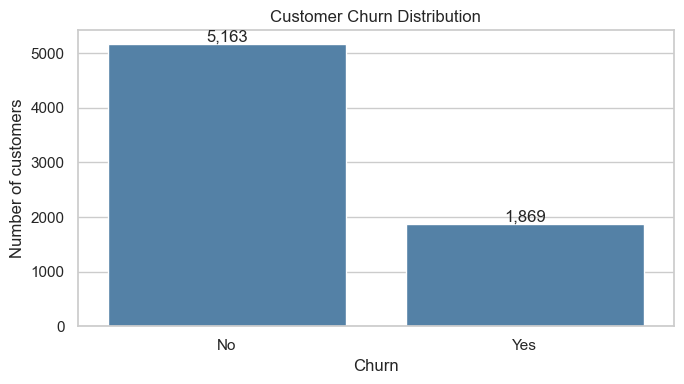

Overall churn rate: 26.6%


In [7]:
churn_counts = df_clean["Churn"].value_counts().reindex(["No", "Yes"])
churn_rate = df_clean["ChurnFlag"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=churn_counts.index, y=churn_counts.values, ax=ax, color="steelblue")
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of customers")
for index, value in enumerate(churn_counts.values):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(f"Overall churn rate: {churn_rate:.1%}")

### Reading the chart

The two bars show how many customers stayed versus left. If the bars are uneven, accuracy alone may be a poor future model metric because a model could favor the larger class. Model evaluation will be handled in a later phase.

## 4. Explore numeric variables

Histograms show the distribution of values. The `hue` setting separates customers who churned from customers who did not, which helps us compare the groups.

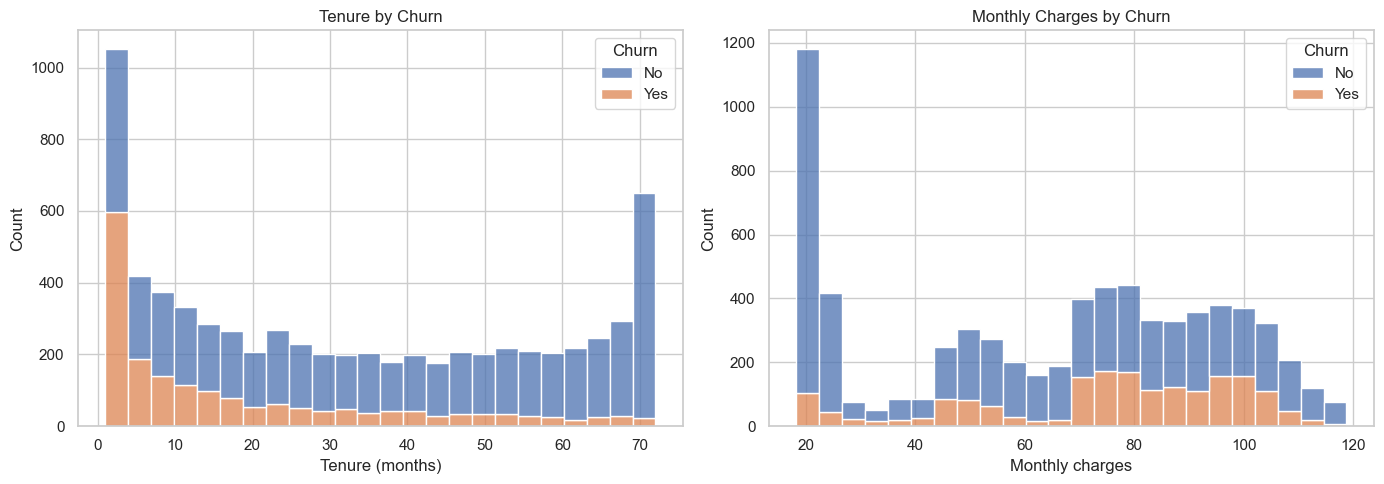

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_clean, x="tenure", hue="Churn", bins=24, multiple="stack", ax=axes[0])
axes[0].set_title("Tenure by Churn")
axes[0].set_xlabel("Tenure (months)")

sns.histplot(data=df_clean, x="MonthlyCharges", hue="Churn", bins=24, multiple="stack", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Monthly charges")

plt.tight_layout()
plt.show()

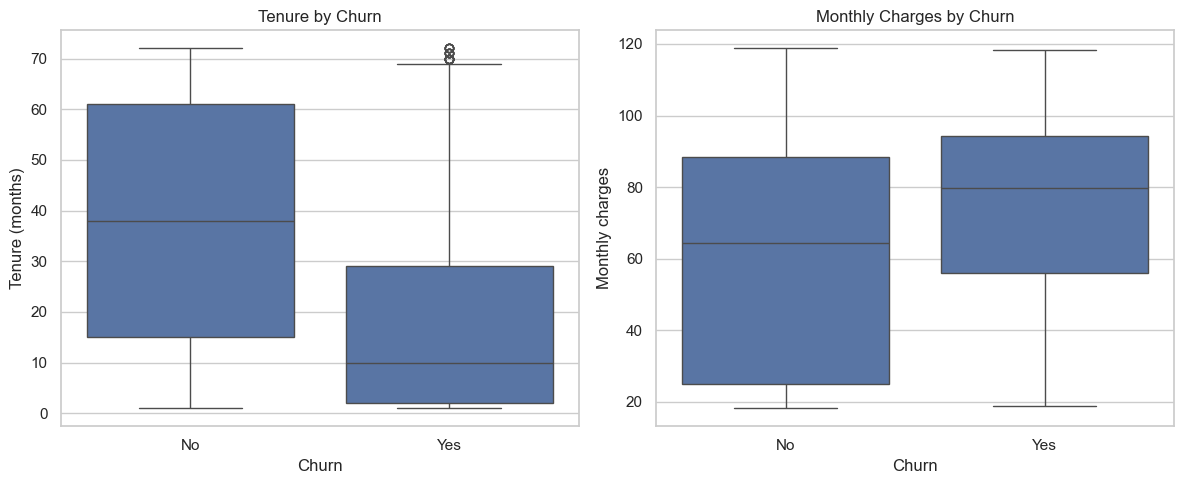

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_clean, x="Churn", y="tenure", ax=axes[0])
axes[0].set_title("Tenure by Churn")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")

sns.boxplot(data=df_clean, x="Churn", y="MonthlyCharges", ax=axes[1])
axes[1].set_title("Monthly Charges by Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly charges")

plt.tight_layout()
plt.show()

Boxplots summarize each group using the middle value and the spread of the data. Look for differences in the typical tenure and monthly charges between churn groups.

## 5. Explore categorical variables

A useful question is: _What percentage of customers churned within each category?_ The next chart calculates a churn rate for contract type, internet service, and payment method. This compares groups fairly even when the groups have different sizes.

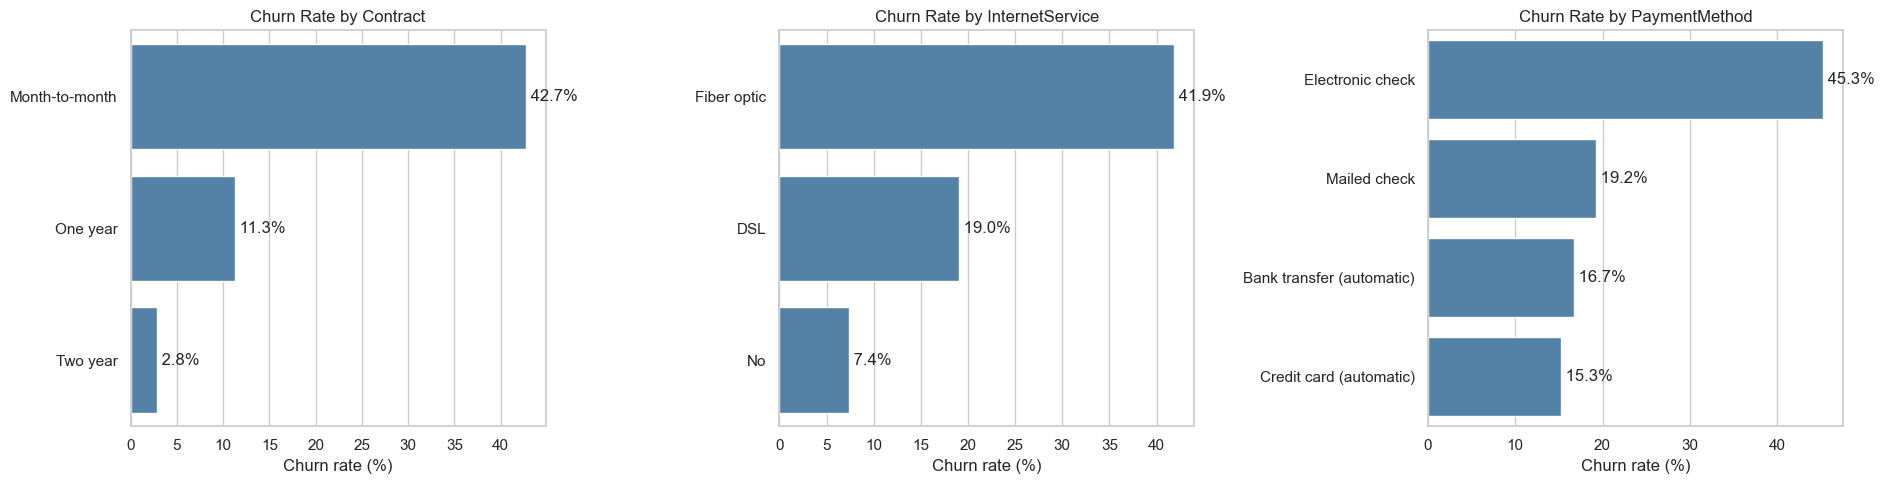

In [10]:
categorical_features = ["Contract", "InternetService", "PaymentMethod"]
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, feature in zip(axes, categorical_features):
    rates = (
        df_clean.groupby(feature, observed=False)["ChurnFlag"]
        .mean()
        .sort_values(ascending=False)
        .mul(100)
    )
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color="steelblue")
    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    for index, value in enumerate(rates.values):
        ax.text(value, index, f" {value:.1f}%", va="center")

plt.tight_layout()
plt.show()

In [11]:
print("Churn rates by selected category:")
for feature in categorical_features:
    summary = (
        df_clean.groupby(feature, observed=False)
        .agg(customers=("ChurnFlag", "size"), churn_rate=("ChurnFlag", "mean"))
        .sort_values("churn_rate", ascending=False)
    )
    summary["churn_rate"] = summary["churn_rate"].mul(100).round(1)
    print(f"\n{feature}")
    display(summary)

Churn rates by selected category:

Contract


,customers,churn_rate
Contract,,
Month-to-month,3875,42.70
One year,1472,11.30
Two year,1685,2.80



InternetService


,customers,churn_rate
InternetService,,
Fiber optic,3096,41.90
DSL,2416,19.00
No,1520,7.40



PaymentMethod


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,45.30
Mailed check,1604,19.20
Bank transfer (automatic),1542,16.70
Credit card (automatic),1521,15.30


## 6. Correlation overview

Correlation measures how two numeric columns move together. It does not establish causation, and it does not work directly with text categories. This heatmap is only a quick numeric overview.

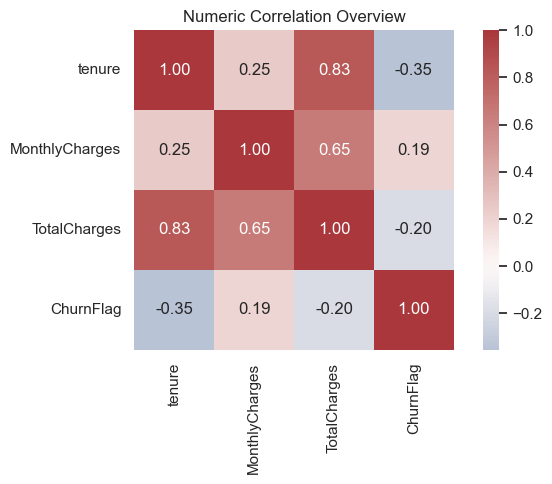

In [12]:
numeric_for_correlation = ["tenure", "MonthlyCharges", "TotalCharges", "ChurnFlag"]
correlation = df_clean[numeric_for_correlation].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Numeric Correlation Overview")
plt.tight_layout()
plt.show()

## 7. Phase 1 summary

At this point we have a clean, inspected dataset and several views of churn. When writing the project report, describe the strongest patterns you observe in the charts, always remembering that these are associations.

### Completed

- Loaded the IBM Telco data.
- Reviewed its structure and missing values.
- Converted `TotalCharges` to numeric.
- Removed unusable rows and the customer identifier.
- Visualized the target, numeric distributions, category-level churn rates, and numeric correlations.

### Deliberately postponed

- Feature encoding and scaling.
- Train/test splitting.
- Model training.
- Model evaluation and tuning.

Those belong in the next phase, after the EDA findings have been reviewed.

### Review notes for Phase 2

- `ChurnFlag` is an EDA-only numeric copy of `Churn`. Exclude both columns from model inputs; use only one as the target.
- Dropping missing `TotalCharges` creates a complete-case EDA subset. Start Phase 2 from the raw data and revisit that exclusion rather than automatically reusing this subset.
- Split the data before fitting imputers, encoders, scalers, feature selection, or resampling. Fit these only on training data (and within each cross-validation fold). Whitespace cleanup and fixed label mappings do not learn population statistics.
- The stacked histograms show customer counts, not churn probabilities. Category charts use within-category churn rates.
- Full-dataset EDA has already exposed target relationships. Keep subsequent test-set evaluation separate from feature and model decisions, and verify that predictors would be available at the intended prediction time.